# 01 · Explore BraTS cases

A first look at the actual image data. We:

1. Load one GLI (adult glioma) case with `nibabel` and inspect the geometry and intensities of each of the four MRI sequences — **t1n, t1c, t2w, t2f**.
2. Inspect the segmentation labels.
3. Plot the four sequences plus the segmentation overlay on the most tumour-heavy axial slice.
4. Repeat for one BraTS-Africa (SSA) case and note how it differs.

## Setup

Load the split index and define a small helper that turns a row of `index.csv` into absolute paths. Paths in the index are stored relative to the data root `C:\data\brats`.

In [1]:
%matplotlib inline
from pathlib import Path
import numpy as np
import pandas as pd
import nibabel as nib
import matplotlib.pyplot as plt
from matplotlib import colors

DATA = Path(r"C:\data\brats")
CWD = Path.cwd()
REPO = CWD if (CWD / "splits" / "index.csv").exists() else CWD.parent

df = pd.read_csv(REPO / "splits" / "index.csv")
MODS = ["t1n", "t1c", "t2w", "t2f"]

def paths_for(row):
    """Absolute paths to the 4 modalities + seg for one index row."""
    return {m: DATA / row[m] for m in MODS + ["seg"]}

print(f"{len(df)} cases in index. Sources: {dict(df['source'].value_counts())}")

1346 cases in index. Sources: {'GLI': np.int64(1251), 'SSA': np.int64(95)}


## 1. Load one GLI case

Pick the first GLI case and load all five volumes. For each MRI sequence we print the array **shape**, the **voxel spacing** (from the NIfTI header, in mm), the **data type**, and the **intensity range**.

In [2]:
gli_row = df[df.source == "GLI"].iloc[0]
gli_paths = paths_for(gli_row)
print(f"Case: {gli_row['case_id']}  (split={gli_row['split']})\n")

gli_imgs = {m: nib.load(str(gli_paths[m])) for m in MODS}

header = f"{'seq':<5} {'shape':<18} {'spacing (mm)':<22} {'dtype':<10} {'intensity range'}"
print(header)
print("-" * len(header))
for m in MODS:
    img = gli_imgs[m]
    arr = img.get_fdata(dtype=np.float32)
    zooms = tuple(round(float(z), 3) for z in img.header.get_zooms()[:3])
    dtype = img.get_data_dtype()
    print(f"{m:<5} {str(arr.shape):<18} {str(zooms):<22} {str(dtype):<10} "
          f"[{arr.min():.1f}, {arr.max():.1f}]")

Case: BraTS-GLI-00000-000  (split=train)

seq   shape              spacing (mm)           dtype      intensity range
--------------------------------------------------------------------------
t1n   (240, 240, 155)    (1.0, 1.0, 1.0)        int16      [0.0, 2023.0]
t1c   (240, 240, 155)    (1.0, 1.0, 1.0)        int16      [0.0, 12343.0]


t2w   (240, 240, 155)    (1.0, 1.0, 1.0)        int16      [0.0, 2421.0]
t2f   (240, 240, 155)    (1.0, 1.0, 1.0)        int16      [0.0, 2934.0]


## 2. Segmentation labels

The BraTS 2023 segmentation uses three foreground labels (0 is background):

| Label | Region |
|-------|--------|
| 1 | Necrotic tumour core (NCR) |
| 2 | Peritumoural oedema (ED) |
| 3 | Enhancing tumour (ET) |

We print the unique values actually present and the voxel count per label.

In [3]:
LABEL_NAMES = {0: "background", 1: "necrotic core", 2: "oedema", 3: "enhancing tumour"}

gli_seg = nib.load(str(gli_paths['seg'])).get_fdata(dtype=np.float32).astype(np.int16)
vals, counts = np.unique(gli_seg, return_counts=True)
print(f"Unique label values: {vals.tolist()}\n")
print(f"{'label':<6} {'name':<18} {'voxels':>12}")
print("-" * 38)
for v, c in zip(vals.tolist(), counts.tolist()):
    print(f"{v:<6} {LABEL_NAMES.get(v, '?'):<18} {c:>12,}")

Unique label values: [0, 1, 2, 3]

label  name                     voxels
--------------------------------------
0      background            8,870,695
1      necrotic core            11,738
2      oedema                   12,836
3      enhancing tumour         32,731


## 3. Visualise the most tumour-heavy axial slice

We find the axial slice (last array axis) containing the most tumour voxels (`seg > 0`) and show the four sequences side by side, plus the segmentation drawn as a coloured overlay on the t1c image.

The helper below is reused for the Africa case further down.

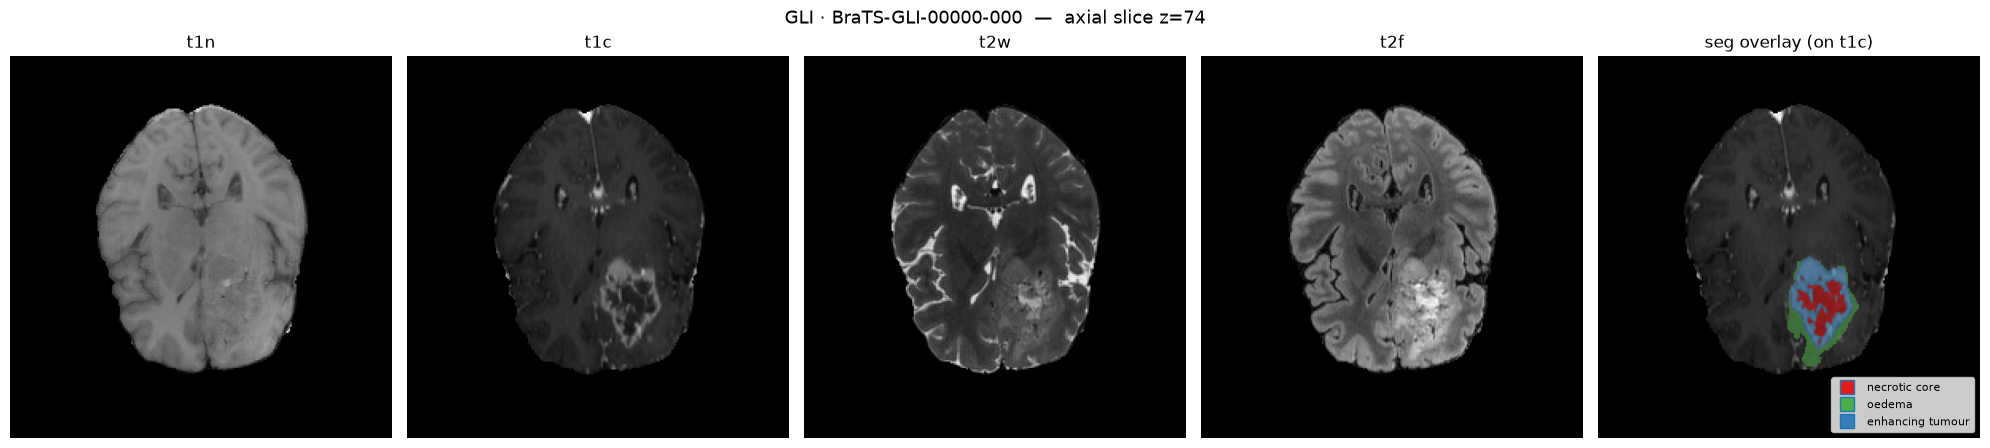

In [4]:
# Discrete colour map for the 3 foreground labels (0 stays transparent).
LABEL_COLORS = {1: "#e41a1c", 2: "#4daf4a", 3: "#377eb8"}  # NCR / ED / ET
_cmap = colors.ListedColormap([LABEL_COLORS[1], LABEL_COLORS[2], LABEL_COLORS[3]])
_norm = colors.BoundaryNorm([0.5, 1.5, 2.5, 3.5], _cmap.N)

def best_axial_slice(seg):
    """Index of the axial slice with the most tumour voxels."""
    return int((seg > 0).sum(axis=(0, 1)).argmax())

def show_case(paths, title):
    """Plot t1n/t1c/t2w/t2f + seg overlay on the most tumour-heavy axial slice."""
    imgs = {m: nib.load(str(paths[m])).get_fdata(dtype=np.float32) for m in MODS}
    seg = nib.load(str(paths['seg'])).get_fdata(dtype=np.float32).astype(np.int16)
    z = best_axial_slice(seg)

    fig, axes = plt.subplots(1, 5, figsize=(20, 4.6))
    for ax, m in zip(axes[:4], MODS):
        sl = np.rot90(imgs[m][:, :, z])
        ax.imshow(sl, cmap="gray")
        ax.set_title(m)
        ax.axis("off")

    # Overlay: seg on top of t1c.
    base = np.rot90(imgs['t1c'][:, :, z])
    seg_sl = np.rot90(seg[:, :, z])
    axes[4].imshow(base, cmap="gray")
    masked = np.ma.masked_where(seg_sl == 0, seg_sl)
    axes[4].imshow(masked, cmap=_cmap, norm=_norm, alpha=0.55)
    axes[4].set_title("seg overlay (on t1c)")
    axes[4].axis("off")

    handles = [plt.Line2D([0], [0], marker="s", linestyle="", markersize=10,
                          markerfacecolor=LABEL_COLORS[k], label=LABEL_NAMES[k])
               for k in (1, 2, 3)]
    axes[4].legend(handles=handles, loc="lower right", fontsize=8, framealpha=0.8)

    fig.suptitle(f"{title}  —  axial slice z={z}", fontsize=13)
    fig.tight_layout()
    plt.show()

show_case(gli_paths, f"GLI · {gli_row['case_id']}")

## 4. A BraTS-Africa (SSA) case

Now the same view for one held-out African case (`external_test`). Both datasets are distributed in the standard BraTS pre-processed space, so we also print a direct geometry / intensity comparison to see what actually differs.

In [5]:
ssa_row = df[df.source == "SSA"].iloc[0]
ssa_paths = paths_for(ssa_row)
print(f"Case: {ssa_row['case_id']}  (split={ssa_row['split']})\n")

def summarise(row, paths):
    out = {}
    for m in MODS:
        img = nib.load(str(paths[m]))
        arr = img.get_fdata(dtype=np.float32)
        out[m] = {
            "shape": arr.shape,
            "spacing": tuple(round(float(z), 3) for z in img.header.get_zooms()[:3]),
            "range": (round(float(arr.min()), 1), round(float(arr.max()), 1)),
        }
    return out

gli_sum = summarise(gli_row, gli_paths)
ssa_sum = summarise(ssa_row, ssa_paths)

print(f"{'seq':<5} {'GLI shape':<16} {'SSA shape':<16} {'GLI spacing':<18} {'SSA spacing':<18}")
print("-" * 73)
for m in MODS:
    print(f"{m:<5} {str(gli_sum[m]['shape']):<16} {str(ssa_sum[m]['shape']):<16} "
          f"{str(gli_sum[m]['spacing']):<18} {str(ssa_sum[m]['spacing']):<18}")
print()
print(f"{'seq':<5} {'GLI intensity':<22} {'SSA intensity':<22}")
print("-" * 49)
for m in MODS:
    print(f"{m:<5} {str(gli_sum[m]['range']):<22} {str(ssa_sum[m]['range']):<22}")

Case: BraTS-SSA-00002-000  (split=external_test)



seq   GLI shape        SSA shape        GLI spacing        SSA spacing       
-------------------------------------------------------------------------
t1n   (240, 240, 155)  (240, 240, 155)  (1.0, 1.0, 1.0)    (1.0, 1.0, 1.0)   
t1c   (240, 240, 155)  (240, 240, 155)  (1.0, 1.0, 1.0)    (1.0, 1.0, 1.0)   
t2w   (240, 240, 155)  (240, 240, 155)  (1.0, 1.0, 1.0)    (1.0, 1.0, 1.0)   
t2f   (240, 240, 155)  (240, 240, 155)  (1.0, 1.0, 1.0)    (1.0, 1.0, 1.0)   

seq   GLI intensity          SSA intensity         
-------------------------------------------------
t1n   (0.0, 2023.0)          (-290.0, 11148.0)     
t1c   (0.0, 12343.0)         (-473.0, 10386.0)     
t2w   (0.0, 2421.0)          (-427.0, 13832.0)     
t2f   (0.0, 2934.0)          (-881.0, 12000.0)     


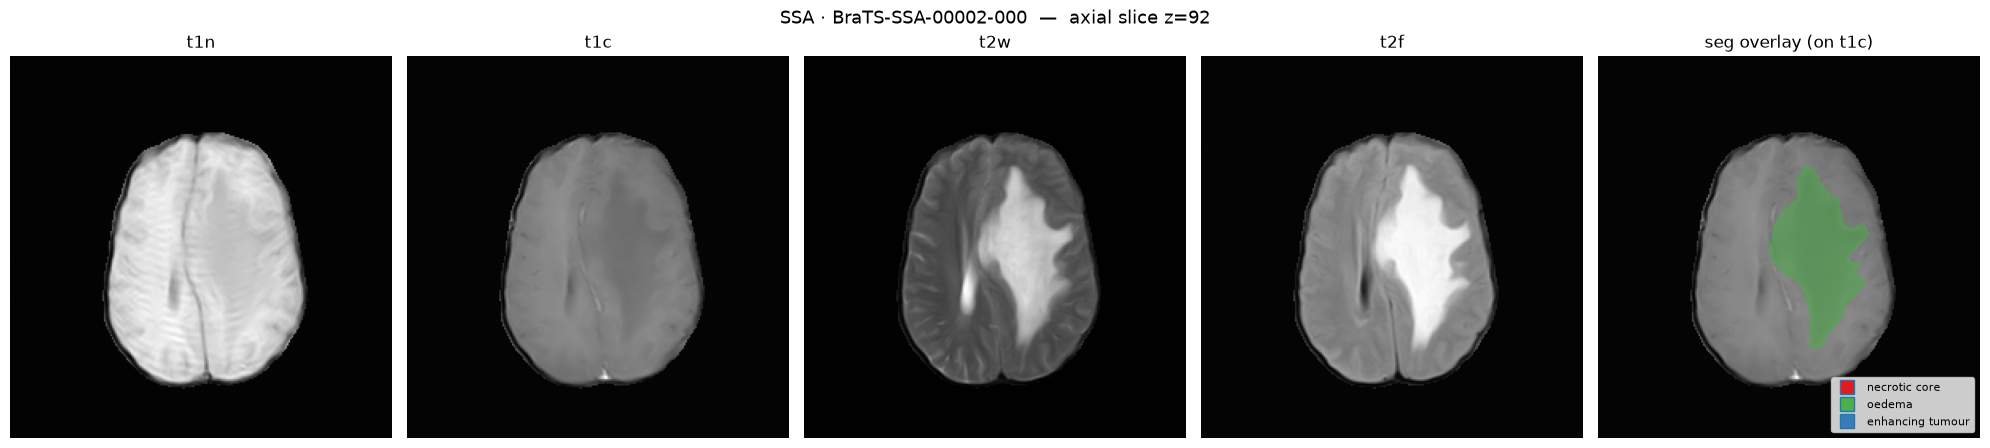

In [6]:
show_case(ssa_paths, f"SSA · {ssa_row['case_id']}")

### How the African (SSA) case differs

Both cases ship in the **same pre-processed BraTS space** — 240×240×155 voxels at 1×1×1 mm, skull-stripped and co-registered — so *on paper* the geometry is identical (the shape/spacing comparison above confirms every sequence matches). The real differences are in **appearance and intensity statistics**:

- **Contrast / tissue separation.** The GLI case has crisp grey–white matter boundaries and strong post-contrast enhancement on t1c. The SSA case looks flatter and lower-contrast: t1n is bright and washed-out, and its t1c is barely distinguishable from t1n (little visible enhancement), so tissue and tumour stand out less from the background.
- **Effective sharpness / SNR.** Although both sit on a 1 mm grid, the SSA volumes look softer and blurrier, with less fine cortical detail — consistent with the lower-field, more heterogeneous scanners behind BraTS-Africa. The nominal resolution is the same; the *effective* resolution is lower.
- **Intensity scale.** The ranges differ sharply. GLI voxels start at exactly 0 with modest maxima, whereas the SSA voxels include **negative values** (down to ≈ −880) and much larger maxima (t1n reaches ≈ 11000 vs ≈ 2000 for GLI). There is no shared intensity normalisation across the two sources, so per-volume normalisation will be essential before any modelling.
- **Tumour make-up (this slice).** Here the SSA tumour is almost entirely oedema (green) with no necrotic core or enhancing tumour, while the GLI case shows all three sub-regions. That is case-specific, not a dataset-wide rule.

Together these are exactly the acquisition / domain shift that makes **BraTS-Africa a meaningful `external_test` set** for studying model robustness.